Financial Complaint Intelligence Platform using NLP

In [4]:
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

%matplotlib inline

## 3. Import NLP Libraries

import re
import string

import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from wordcloud import WordCloud


### Explanation

# * **re** → Regular expressions for text cleaning.
# * **string** → Punctuation handling.
# * **stopwords** → Removes common words like *the*, *is*, *and*.
# * **WordNetLemmatizer** → Converts words to their base form.
# * **word_tokenize()** → Splits text into words.
# * **WordCloud** → Visual representation of frequently occurring words.

Download NLTK Resources

In [5]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to /Users/Dataghost/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/Dataghost/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/Dataghost/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/Dataghost/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/Dataghost/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [6]:
from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.pipeline import Pipeline

* **train_test_split()** → Splits dataset into training and testing sets.
* **CountVectorizer** → Bag of Words representation.
* **TfidfVectorizer** → TF-IDF feature extraction.
* **Pipeline** → Combines preprocessing and model training into one workflow.

In [7]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [8]:
print("NumPy Version      :", np.__version__)
print("Pandas Version     :", pd.__version__)
print("NLTK Version       :", nltk.__version__)
print("Seaborn Version    :", sns.__version__)

NumPy Version      : 2.4.6
Pandas Version     : 3.0.3
NLTK Version       : 3.10.0
Seaborn Version    : 0.13.2


In [9]:
df = pd.read_csv("complaints_processed.csv")

df.head().style.background_gradient(cmap='viridis')

,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order shipped several week stock since early due high demand although continuing take order guaranteeing receive order place due time mask order exact shipping date right however guarantee ship soon soon delivers product u getting small shipment shipping first come first served basis appreciate patience fulfill order quickly recommend keeping order lose place line cancel distributor stock moment prefer cancel please note ask via email cancel accordance cancellation policy agreed checkout electronic inventory online requested order canceled refund issued canceled order sent verification order canceled refunded item particulate respirator refunded subtotal shipping tax total usd visa ending refund called disputed amount stated nothing needed submitted address issue recharged item removing called back dispute amount transaction rebillmerchandiserobert ca purchased thu posted wed purchased appears statement transaction rebill ca u followed see status case submitted documentation showing canceled order supposed submit refund called back speak manager case stated dispute ruled favor charge removed card capital one removed purchase bill purchase adjustmentmerchandiserobert j posted fri purchased appears statement purchase adjustment capital one recharges amount transaction rebillmerchandiserobert j purchased thu posted mon purchased appears statement transaction rebill called capital one requested recharge stated visa ruled case pretended remove purchase knew anything case manager ruling favor
1,1,credit_card,forwarded message date tue subject please investigate comenity bank retailer card scam sent hello name scammed comenity bank credit card provider company childrens place new york forever victoria secret original credit comenity bank lower limit began charge overage fee along late fee began pay close attention card find limit also changed well incurring overage late fee reached company comenity bank stated would change credit limit original limit reached told summit payment account corrected comenity bank credit card impacted credit score plummeted negative status im currently paying price due corruption affected detrimental way debt due company charging overage fee well late fee even initial credit limit fluctuating tremendously company charge major fee account willing correct account nervous said attorney reason im reaching im employee company ruining credit plz help name contact info thank
2,2,retail_banking,forwarded message cc sent friday pdt subject final legal payment well fargo well fargo clearly wrong need look actually opened account see court hearing several different government agency reporting well including branch put open account numerous fraudulent charge debit card connected account clearly due fact well fargo maintain clearly required encryption card keep secure adding damage request small claim lawsuit time take away running business branch required come branch multiple time get fraudulent charge removed actually present strong case proper consumer protection agency well fargo immediately barred issuing account debit card insure agency card adequate prevent fraudulent use also requesting punitive treble damage sum hour take work handle lawsuit along legal cost filing lawsuit county small claim court today well fargo outrageous fraudulent conduct clearly warrant punitive damage also sharing every possible consumer protection agency find would think well fargo enough adverse publicity fraudulent conduct last year introduce small claim suit clearly establishing well fargo established business practice fraud customer ca judge really need reminded might want immediately run bonus payment legal department
3,3,credit_reporting,payment history missing credit report specialized loan s

In [10]:
df.head(10)

,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...
5,5,credit_reporting,payment history missing credit report made mis...
6,6,credit_reporting,va date complaint experian credit bureau invol...
7,7,credit_reporting,account reported abbreviated name full name se...
8,8,credit_reporting,account reported abbreviated name full name se...
9,9,credit_reporting,usdoexxxx account reported abbreviated name fu...


In [11]:
df['product'].value_counts()

product
credit_reporting       91179
debt_collection        23150
mortgages_and_loans    18990
credit_card            15566
retail_banking         13536
Name: count, dtype: int64

In [12]:
df.tail().style.background_gradient(cmap='viridis')

,Unnamed: 0,product,narrative
162416,162416,debt_collection,name
162417,162417,credit_card,name
162418,162418,debt_collection,name
162419,162419,credit_card,name
162420,162420,credit_reporting,name


In [13]:
print("Rows :", df.shape[0])

print("Columns :", df.shape[1])

Rows : 162421
Columns : 3


In [14]:
df.columns

Index(['Unnamed: 0', 'product', 'narrative'], dtype='str')

Understanding the Columns

| Column     | Meaning                       |
| ---------- | ----------------------------- |
| Unnamed: 0 | Old index column (not useful) |
| product    | Target variable               |
| narrative  | Complaint text                |

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 162421 entries, 0 to 162420
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   Unnamed: 0  162421 non-null  int64
 1   product     162421 non-null  str  
 2   narrative   162411 non-null  str  
dtypes: int64(1), str(2)
memory usage: 97.3 MB


Statistical Summary

In [16]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,162421.0,NaN,NaN,NaN,81210.0,46887.048373,0.0,40605.0,81210.0,121815.0,162420.0
product,162421,5,credit_reporting,91179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
narrative,162411,124472,victim identity notified collection creditor s...,739,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Since this is mostly text data, using `include="all"` provides useful information about categorical columns as well.

Memory Usage

In [17]:
memory = df.memory_usage(deep=True).sum() / 1024**2

print(f"Dataset Size : {memory:.2f} MB")

Dataset Size : 97.30 MB


Why is this important?

Large NLP datasets can consume significant memory. Knowing the size helps determine whether optimization or sampling is needed.

Missing Values

In [18]:
df.isnull().sum()

Unnamed: 0     0
product        0
narrative     10
dtype: int64

In [19]:
missing = pd.DataFrame({

    "Missing Values": df.isnull().sum(),
    
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing

,Missing Values,Percentage
Unnamed: 0,0,0.000000
product,0,0.000000
narrative,10,0.006157


missing values exist in the `narrative` column, we will handle them before preprocessing.

Duplicate Records

In [20]:
duplicates = df.duplicated().sum()

print("Duplicate Rows :", duplicates)

Duplicate Rows : 0


Remove Unnecessary Column

In [21]:
df.drop("Unnamed: 0", axis=1, inplace=True)

In [22]:
df.head()

,product,narrative
0,credit_card,purchase order day shipping amount receive pro...
1,credit_card,forwarded message date tue subject please inve...
2,retail_banking,forwarded message cc sent friday pdt subject f...
3,credit_reporting,payment history missing credit report speciali...
4,credit_reporting,payment history missing credit report made mis...


Check Unique Categories

In [23]:
df["product"].unique()

<ArrowStringArray>
[        'credit_card',      'retail_banking',    'credit_reporting',
 'mortgages_and_loans',     'debt_collection']
Length: 5, dtype: str

In [24]:
print("Number of Categories :", df["product"].nunique())

Number of Categories : 5


This tells us whether the problem is:

* Binary Classification
* Multi-Class Classification
* Multi-Label Classification

In our case, it is a **multi-class text classification** problem.

Class Distribution

In [25]:
df["product"].value_counts()

product
credit_reporting       91179
debt_collection        23150
mortgages_and_loans    18990
credit_card            15566
retail_banking         13536
Name: count, dtype: int64

This shows how many complaints belong to each financial product category.

Check Text Samples

In [26]:
for i in range(5):
    
    print("=" * 80)
    print("Category :", df["product"].iloc[i])
    print("\nComplaint:\n")
    print(df["narrative"].iloc[i])
    print()

Category : credit_card

Complaint:

purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order shipped several week stock since early due high demand although continuing take order guaranteeing receive order place due time mask order exact shipping date right however guarantee ship soon soon delivers product u getting small shipment shipping first come first served basis appreciate patience fulfill order quickly recommend keeping order lose place line cancel distributor stock moment prefer cancel please note ask via email cancel accordance cancellation policy agreed checkout electronic inventory online requested order canceled refund issued canceled order sent verification order canceled refunded item particulate respirator refunded subtotal shipping tax total usd visa ending refund called disputed amount stated nothing needed submitted address is

Before cleaning, it is important to identify:

* URLs
* Email addresses
* HTML tags
* Punctuation
* Numbers
* Placeholder tokens (e.g., `xxxx`)
* Extra spaces
* Other noise

Understanding the raw text helps design an effective preprocessing pipeline.

Exploratory Data Analysis (EDA)

In [27]:
df.head()

,product,narrative
0,credit_card,purchase order day shipping amount receive pro...
1,credit_card,forwarded message date tue subject please inve...
2,retail_banking,forwarded message cc sent friday pdt subject f...
3,credit_reporting,payment history missing credit report speciali...
4,credit_reporting,payment history missing credit report made mis...


Number of Complaint Categories

In [28]:
print("Number of Complaint Categories :", df["product"].nunique())

Number of Complaint Categories : 5


In [29]:
categories = df["product"].unique()

for category in categories:
    print(category)

credit_card
retail_banking
credit_reporting
mortgages_and_loans
debt_collection


Business Insight

Banks receive complaints across multiple financial products.

Our AI model must correctly identify which department should receive each complaint.

Complaint Category Distribution

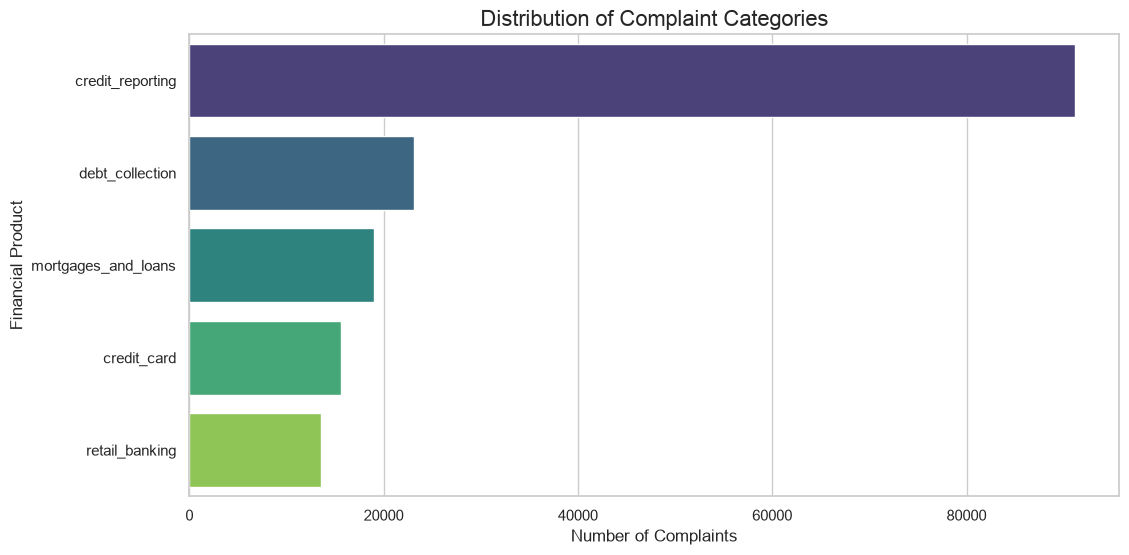

In [30]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    y="product",
    order=df["product"].value_counts().index,
    palette="viridis"
)

plt.title("Distribution of Complaint Categories", fontsize=16)

plt.xlabel("Number of Complaints")

plt.ylabel("Financial Product")

plt.show()

Expected Insight

Typically,

* Mortgage
* Credit Reporting
* Debt Collection

receive the highest number of complaints.

This indicates **class imbalance**, which will influence model selection and evaluation.

Complaint Percentage

In [31]:
complaints = df["product"].value_counts()

percentage = round(
    complaints/len(df)*100,
    2
)

pd.DataFrame({
    "Complaints":complaints,
    "Percentage":percentage
})

,Complaints,Percentage
product,,
credit_reporting,91179,56.14
debt_collection,23150,14.25
mortgages_and_loans,18990,11.69
credit_card,15566,9.58
retail_banking,13536,8.33


This table provides a clearer understanding of the relative frequency of each complaint category.

Character Count


Each complaint varies in length.

Let's calculate character count.

In [32]:
print("Before:", df.shape)

Before: (162421, 2)


In [33]:
df = df.dropna(subset=["narrative"])

df.reset_index(drop=True, inplace=True)


In [34]:

print("After:", df.shape)

print("Missing narratives:", df["narrative"].isnull().sum())

After: (162411, 2)
Missing narratives: 0


In [35]:
df["Character_Count"] = df["narrative"].apply(len)

In [36]:
df.head()

,product,narrative,Character_Count
0,credit_card,purchase order day shipping amount receive pro...,1705
1,credit_card,forwarded message date tue subject please inve...,904
2,retail_banking,forwarded message cc sent friday pdt subject f...,1230
3,credit_reporting,payment history missing credit report speciali...,903
4,credit_reporting,payment history missing credit report made mis...,851


In [37]:
df[["narrative","Character_Count"]].head()

,narrative,Character_Count
0,purchase order day shipping amount receive pro...,1705
1,forwarded message date tue subject please inve...,904
2,forwarded message cc sent friday pdt subject f...,1230
3,payment history missing credit report speciali...,903
4,payment history missing credit report made mis...,851


Character Count Distribution

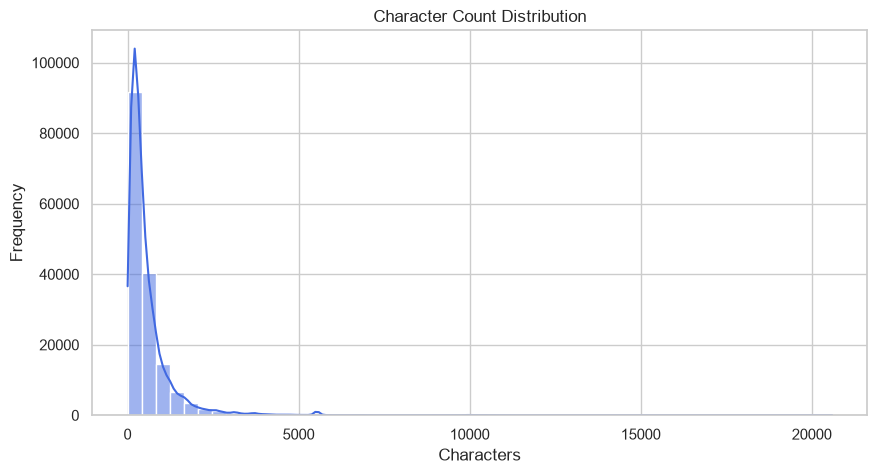

In [38]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["Character_Count"],
    bins=50,
    kde=True,
    color="royalblue"
)

plt.title("Character Count Distribution")

plt.xlabel("Characters")

plt.ylabel("Frequency")

plt.show()

Business Insight

Some complaints are only one sentence.

Others are long legal explanations.

Our NLP pipeline should work well for both.

Word Count

In [39]:
df["Word_Count"] = df["narrative"].apply(
    
    lambda x: len(str(x).split())
)

In [40]:
df[["Word_Count"]].head()

,Word_Count
0,230
1,132
2,173
3,131
4,123


Word Count Distribution

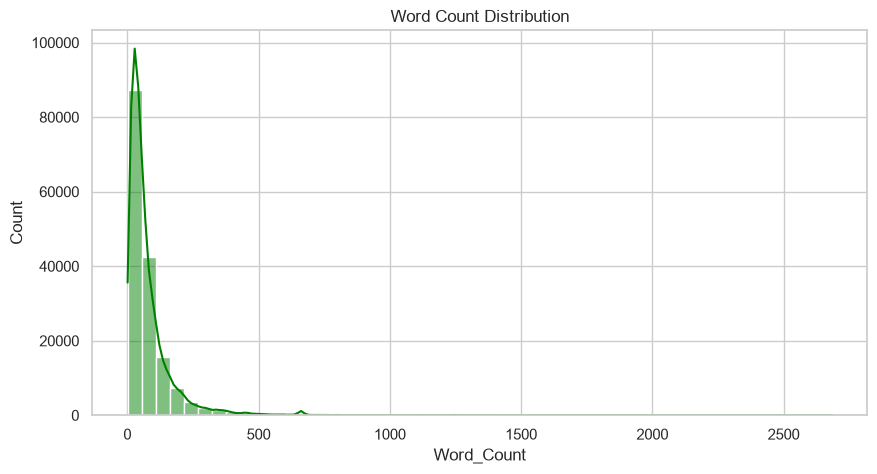

In [41]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["Word_Count"],
    bins=50,
    kde=True,
    color="green"
)

plt.title("Word Count Distribution")

plt.show()

Sentence Count

Sentence count helps understand document complexity.

In [42]:
import re

df["Sentence_Count"] = df["narrative"].apply(
    lambda x: len([s for s in re.split(r"[.!?]+", str(x).strip()) if s.strip()])
)


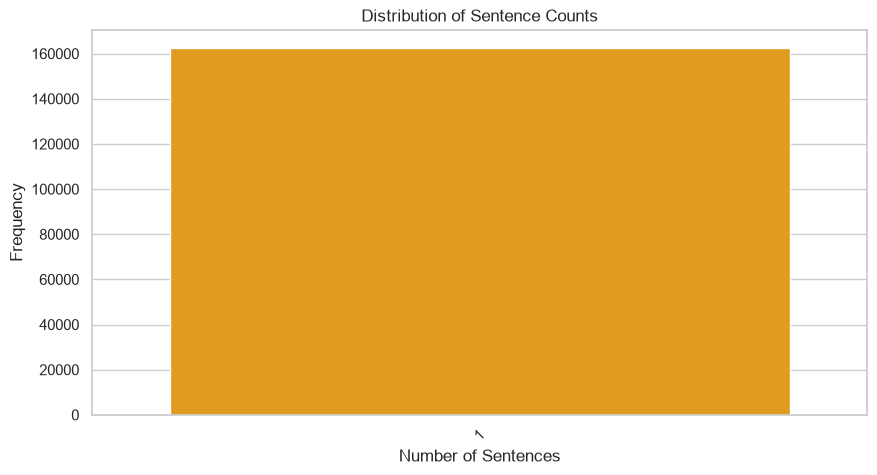

In [43]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Sentence_Count",
    color="orange"
)

plt.title("Distribution of Sentence Counts")
plt.xlabel("Number of Sentences")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.show()


Average Word Length

In [44]:
df["Average_Word_Length"] = df["narrative"].apply(

    lambda x:

    np.mean(

        [len(word)

         for word in str(x).split()]

    )

)

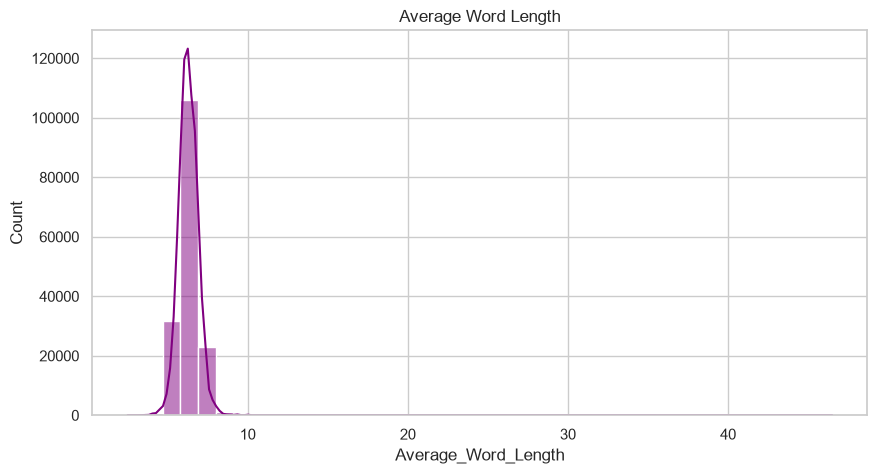

In [45]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["Average_Word_Length"],
    bins=40,
    kde=True,
    color="purple"
)

plt.title("Average Word Length")

plt.show()

Statistical Summary

In [46]:
df[
    [
        "Character_Count",
        "Word_Count",
        "Sentence_Count",
        "Average_Word_Length"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
Character_Count,162411.0,588.535838,830.977413,3.0,192.000000,361.00000,683.000000,20596.0
Word_Count,162411.0,80.232798,108.872213,1.0,27.000000,50.00000,95.000000,2685.0
Sentence_Count,162411.0,1.000000,0.000000,1.0,1.000000,1.00000,1.000000,1.0
Average_Word_Length,162411.0,6.291965,0.622877,2.5,5.895405,6.27451,6.682927,46.5


Boxplots


Character Count

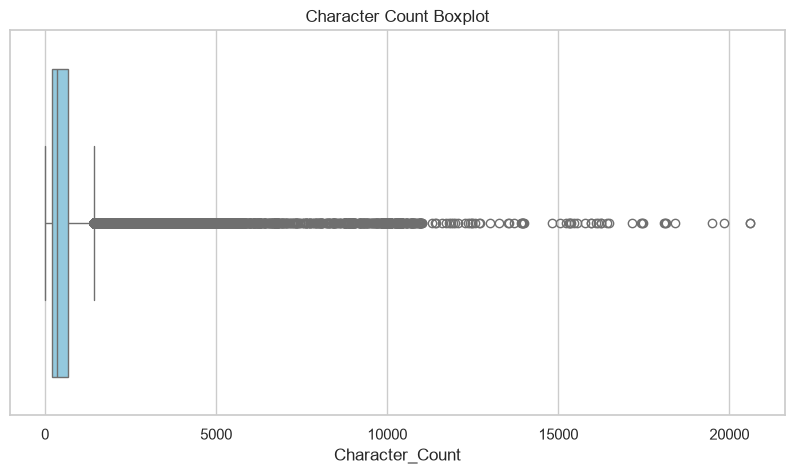

In [47]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x=df["Character_Count"],
    color="skyblue"
)

plt.title("Character Count Boxplot")

plt.show()

Word Count

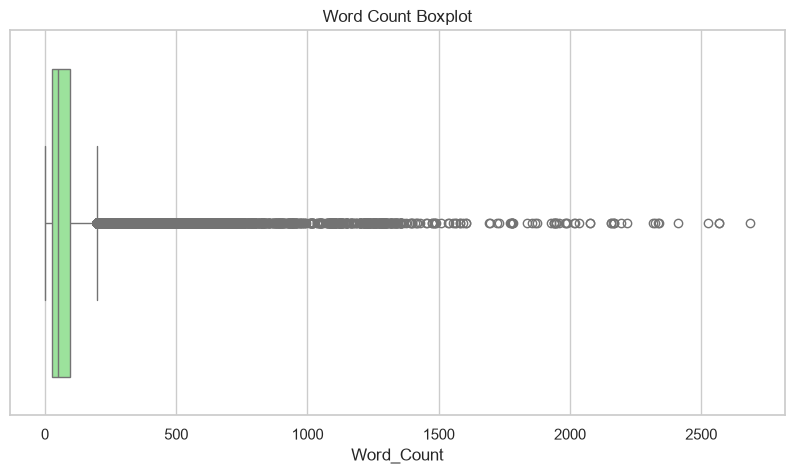

In [48]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x=df["Word_Count"],
    color="lightgreen"
)

plt.title("Word Count Boxplot")

plt.show()

learn

* Outliers

* Skewness

* Distribution

Correlation Between Text Features

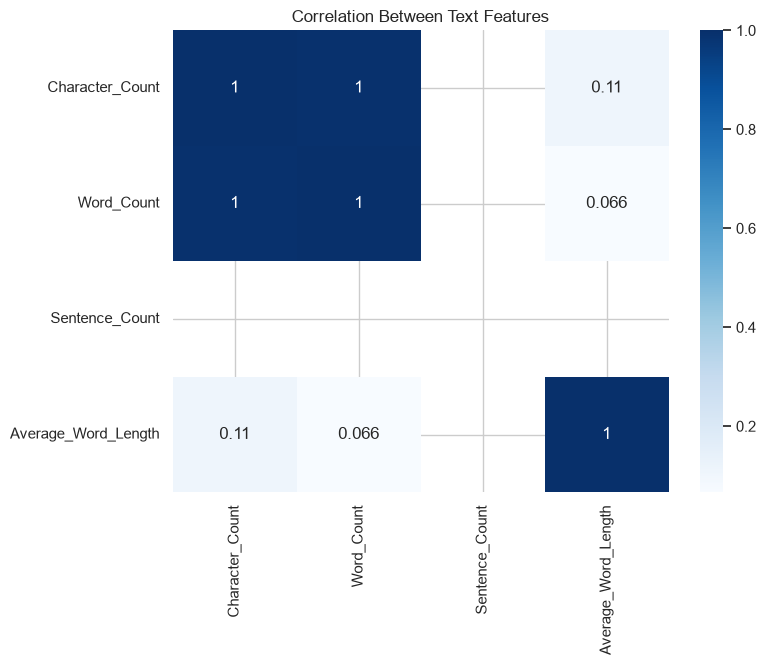

In [49]:
features = df[
    [
        "Character_Count",
        "Word_Count",
        "Sentence_Count",
        "Average_Word_Length"
    ]
]

plt.figure(figsize=(8,6))

sns.heatmap(
    features.corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Between Text Features")

plt.show()

Notice:

* Character Count and Word Count are highly correlated.
* Sentence Count generally increases with Word Count.
* Average Word Length may have a weaker relationship.


This helps explain why some engineered features may be redundant or complementary.

Longest Complaint

In [50]:
longest = df.loc[df["Word_Count"].idxmax()]

print("Category:", longest["product"])
print()
print(longest["narrative"])

Category: mortgages_and_loans

please refer full detail written within page pdf included better explain full length detail hi name wanted first thank time consideration care list valid complaint violation unrefutable proof support claim entirety also would like apologize ranting ahead time seeing still trailing severely excrutiating amount frustration disgust disgruntlement way mistreated uncared carvana house lender carvana warantee company much absolutely best highly unethical illegal potentially even criminal worst given valid plethora proof takeaway thru experience business carvana representative complaint surround mainly carvana llc also house lender affiliate handling many lending law company like carvana llc house lender bound follow ensure proper escallation guideline place exhausted properly document resolve prevent overt impact brought onto client law regulation violation claiming carvana clearly intentionally severely violated without doubt udaap unfair deceptive act practic

Shortest Complaint

In [51]:

shortest = df.loc[df["Word_Count"].idxmin()]

print("Category:", shortest["product"])
print()
print(shortest["narrative"])

Category: credit_reporting

account


Business Insights

From this EDA, we can conclude:

* Complaint volumes differ significantly by product category.
* The dataset is **multi-class** and likely **imbalanced**.
* Complaint lengths vary widely.
* Longer complaints may contain richer contextual information.
* Feature engineering based on text length can be useful.
* Proper preprocessing is essential before vectorization.

This will be one of the most detailed sections of the notebook, where we'll build a reusable NLP preprocessing function covering:

* Lowercasing
* HTML removal
* URL removal
* Email removal
* Number removal
* Punctuation removal
* Emoji removal
* Special character cleaning
* Tokenization
* Stopword removal
* Lemmatization
* Final cleaned text generation

This cleaned text will become the input for feature extraction and machine learning.


NLP Text Preprocessing Pipeline

Learning Objective

Raw text is messy. Before converting text into numerical features (TF-IDF, CountVectorizer, etc.), we need to clean and normalize it.

In this section, we'll build a **production-ready preprocessing pipeline** that can be reused for any NLP project.

We'll transform this:

```text
I visited www.bank.com yesterday!!! They charged me $500 twice 😡.
Please contact me at john@gmail.com.
```

into:

```text
visit bank yesterday charge twice please contact
```

NLP Pipeline Overview

```
Raw Text
    │
    ▼
Lowercase
    │
    ▼
Remove HTML Tags
    │
    ▼
Remove URLs
    │
    ▼
Remove Email IDs
    │
    ▼
Remove Numbers
    │
    ▼
Remove Punctuation
    │
    ▼
Remove Special Characters
    │
    ▼
Remove Extra Spaces
    │
    ▼
Tokenization
    │
    ▼
Stopword Removal
    │
    ▼
Lemmatization
    │
    ▼
Clean Text
```

Create a Copy of the Original Dataset

Never modify the original text directly.

In [52]:
df_clean = df.copy()

View Original Complaint

In [53]:
sample_text = df_clean["narrative"].iloc[0]

print(sample_text)

purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order shipped several week stock since early due high demand although continuing take order guaranteeing receive order place due time mask order exact shipping date right however guarantee ship soon soon delivers product u getting small shipment shipping first come first served basis appreciate patience fulfill order quickly recommend keeping order lose place line cancel distributor stock moment prefer cancel please note ask via email cancel accordance cancellation policy agreed checkout electronic inventory online requested order canceled refund issued canceled order sent verification order canceled refunded item particulate respirator refunded subtotal shipping tax total usd visa ending refund called disputed amount stated nothing needed submitted address issue recharged item removing called b

observe:

* Uppercase letters
* Numbers
* Special characters
* Punctuation
* URLs
* HTML (if present)
* Placeholder words like `xxxx`

Convert Text to Lowercase

Machine Learning treats

```
Bank
BANK
bank
```

as three different words.

Convert everything to lowercase.

In [54]:
df_clean["clean_text"] = df_clean["narrative"].str.lower()

In [55]:
print(df_clean["clean_text"].iloc[0])

purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order shipped several week stock since early due high demand although continuing take order guaranteeing receive order place due time mask order exact shipping date right however guarantee ship soon soon delivers product u getting small shipment shipping first come first served basis appreciate patience fulfill order quickly recommend keeping order lose place line cancel distributor stock moment prefer cancel please note ask via email cancel accordance cancellation policy agreed checkout electronic inventory online requested order canceled refund issued canceled order sent verification order canceled refunded item particulate respirator refunded subtotal shipping tax total usd visa ending refund called disputed amount stated nothing needed submitted address issue recharged item removing called b

Remove HTML Tags

Sometimes datasets contain HTML.

Example

```html
<p>Your account</p>
```

should become

```
Your account
```

In [56]:
def remove_html(text):

    clean = re.compile("<.*?>")

    return re.sub(clean, "", text)

In [57]:
df_clean["clean_text"] = df_clean["clean_text"].apply(remove_html)

Remove URLs


Example

```
https://bank.com
```

should disappear.

In [58]:
def remove_urls(text):

    return re.sub(
        r"http\S+|www\S+|https\S+",
        "",
        text
    )

In [59]:
df_clean["clean_text"] = df_clean["clean_text"].apply(remove_urls)

Remove Email Addresses

Example

```
abc@gmail.com
```

In [60]:
def remove_email(text):

    return re.sub(
        r"\S+@\S+",
        "",
        text
    )

In [61]:
df_clean["clean_text"] = df_clean["clean_text"].apply(remove_email)

Remove Numbers

Numbers generally don't help classify complaint topics.

In [62]:
def remove_numbers(text):

    return re.sub(r"\d+", "", text)

In [63]:
df_clean["clean_text"] = df_clean["clean_text"].apply(remove_numbers)

Remove Punctuation

In [64]:
def remove_punctuation(text):

    return text.translate(

        str.maketrans(
            "",
            "",
            string.punctuation
        )

    )

In [65]:
df_clean["clean_text"] = df_clean["clean_text"].apply(remove_punctuation)

Remove Extra Spaces

Cleaning often leaves multiple spaces.

In [66]:
def remove_spaces(text):

    return re.sub(
        r"\s+",
        " ",
        text
    ).strip()

In [67]:
df_clean["clean_text"] = df_clean["clean_text"].apply(remove_spaces)

Remove Placeholder Words

This CFPB dataset contains masked words like:

```
xxxx
xxxxx
xx
```

These are not meaningful.

In [68]:
def remove_masked_words(text):

    return re.sub(

        r"\b(x+)\b",

        "",

        text

    )

In [69]:
df_clean["clean_text"] = df_clean["clean_text"].apply(remove_masked_words)

Remove spaces again

In [70]:
df_clean["clean_text"] = df_clean["clean_text"].apply(remove_spaces)

Tokenization


Convert sentence into words.

In [71]:
df_clean["tokens"] = df_clean["clean_text"].apply(word_tokenize)

Example

```
I love NLP
```

↓

```
["I","love","NLP"]
```

Stopword Removal

Create stopword list

In [72]:
stop_words = set(stopwords.words("english"))

def remove_stopwords(tokens):

    return [

        word

        for word in tokens

        if word not in stop_words

    ]

In [73]:
df_clean["tokens"] = df_clean["clean_text"].str.split()

Why?

Words like

```
the

is

are

was

were

to

for

of
```

appear frequently but contribute little to classification.

Lemmatization

Create lemmatizer

In [74]:
lemmatizer = WordNetLemmatizer()

def lemmatize_words(tokens):

    return [

        lemmatizer.lemmatize(word)

        for word in tokens

    ]

In [75]:
df_clean["tokens"] = df_clean["tokens"].apply(lemmatize_words)

 Example

```
running
runs
ran
```

↓

```
run
```

```
cars
```

↓

```
car
```

Join Tokens Back Into Text

Machine Learning models expect strings, not token lists.

In [76]:
df_clean["clean_text"] = df_clean["tokens"].apply(

    lambda words:

    " ".join(words)

)

Compare Original vs Cleaned Text

In [77]:
comparison = pd.DataFrame({

    "Original":

    df["narrative"].head(5),

    "Cleaned":

    df_clean["clean_text"].head(5)

})

comparison

,Original,Cleaned
0,purchase order day shipping amount receive pro...,purchase order day shipping amount receive pro...
1,forwarded message date tue subject please inve...,forwarded message date tue subject please inve...
2,forwarded message cc sent friday pdt subject f...,forwarded message cc sent friday pdt subject f...
3,payment history missing credit report speciali...,payment history missing credit report speciali...
4,payment history missing credit report made mis...,payment history missing credit report made mis...


Check Empty Complaints

Sometimes aggressive cleaning removes almost everything.

In [78]:
empty = df_clean[
    df_clean["clean_text"].str.len() == 0
]

print("Empty Complaints :", len(empty))

Empty Complaints : 0


In [79]:
df_clean = df_clean[
    
    df_clean["clean_text"].str.len() > 0
]

Save Clean Dataset

In [80]:
df_clean.to_csv(

    "complaints_cleaned.csv",

    index=False

)

print("Clean dataset saved successfully.")

Clean dataset saved successfully.


* Why preprocessing is necessary
* Lowercasing
* HTML removal
* URL removal
* Email removal
* Number removal
* Punctuation removal
* Whitespace normalization
* Removal of CFPB placeholder tokens (`xxxx`)
* Tokenization
* Stopword removal
* Lemmatization
* Reconstruction of cleaned text
* Validation of cleaned output

At the end of this step, `clean_text` is ready for **exploratory text visualization** and **feature extraction**.

Advanced NLP Visualizations

Before building machine learning models, it's essential to understand the vocabulary and linguistic patterns in the dataset.

By the end of this section, students will know:

* Which words appear most frequently
* Which word combinations (bigrams/trigrams) dominate
* What customers complain about the most
* How complaint categories differ
* Whether preprocessing improved the text

Combine All Cleaned Text

Many visualizations require a single corpus.

In [81]:
all_text = " ".join(df_clean["clean_text"])

print("Total Characters :", len(all_text))

Total Characters : 95678155


Generate Word Cloud

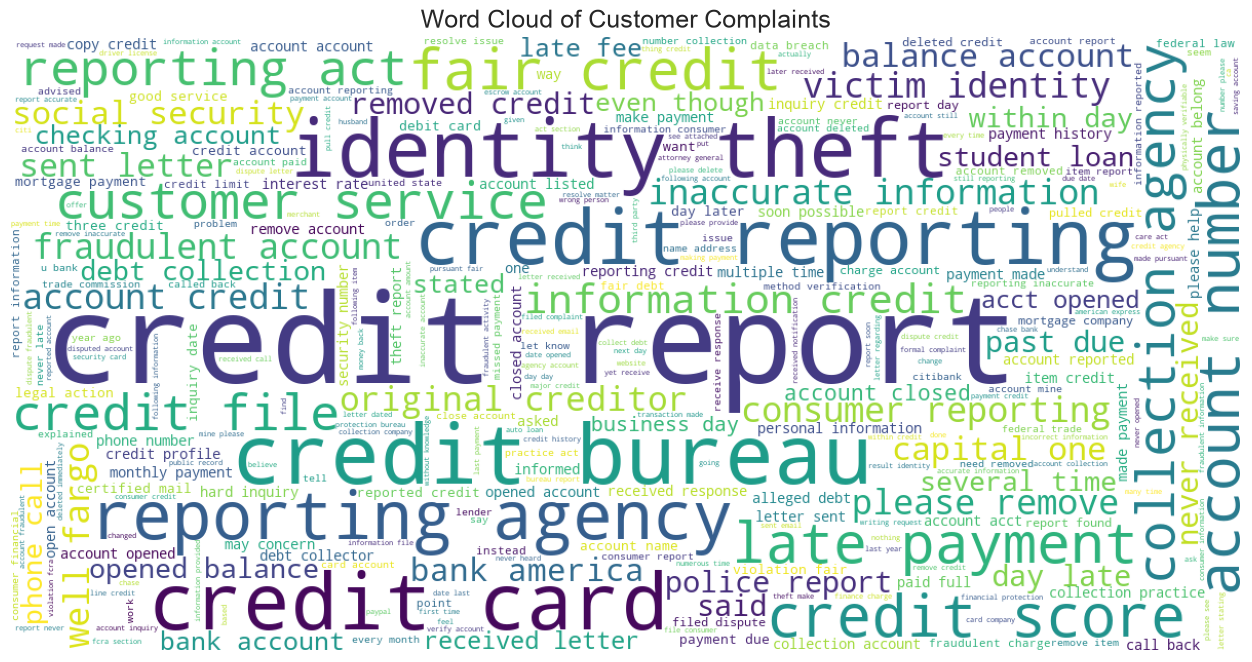

In [82]:
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=300,
    colormap="viridis"
).generate(all_text)

plt.figure(figsize=(16,8))

plt.imshow(wordcloud)

plt.axis("off")

plt.title("Word Cloud of Customer Complaints",
          fontsize=18)

plt.show()

identify common financial terms like:

* account
* payment
* loan
* credit
* report
* bank
* collection
* company
* balance

These represent the dominant themes in the complaints.

Top 30 Most Frequent Words

In [83]:
from collections import Counter

Split into words.

In [84]:
words = all_text.split()

word_freq = Counter(words)

Top 30 words

In [85]:
top_words = pd.DataFrame(

    word_freq.most_common(30),

    columns=["Word","Frequency"]

)

top_words

,Word,Frequency
0,credit,317561
1,account,316151
2,report,177193
3,information,143538
4,payment,127704
5,reporting,94522
6,time,82905
7,company,79449
8,would,78230
9,day,77044


Visualize Top Words

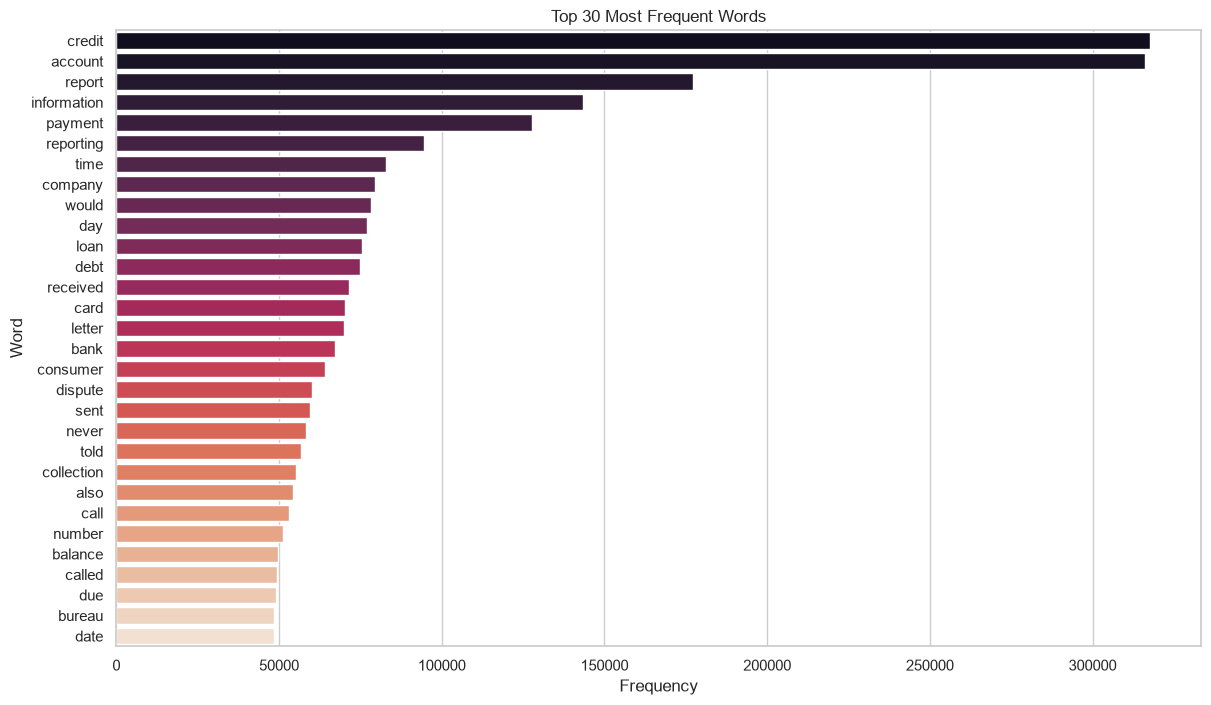

In [86]:
plt.figure(figsize=(14,8))

sns.barplot(

    data=top_words,

    y="Word",

    x="Frequency",

    palette="rocket"

)

plt.title("Top 30 Most Frequent Words")

plt.show()

* Why does **account** appear frequently?
* Why are **payment**, **credit**, and **loan** common?
* What does this indicate about banking complaints?

In [87]:
from sklearn.feature_extraction.text import CountVectorizer

Most Frequent Bigrams

In [88]:
bigram = CountVectorizer(

    ngram_range=(2,2),

    max_features=20

)

X = bigram.fit_transform(df_clean["clean_text"])

Frequency

In [89]:
bigram_counts = pd.DataFrame(

    X.sum(axis=0).A1,

    index=bigram.get_feature_names_out(),

    columns=["Frequency"]

)

bigram_counts = bigram_counts.sort_values(

    by="Frequency",

    ascending=False

)

bigram_counts.head(20)

,Frequency
credit report,99346
credit bureau,31339
identity theft,29018
credit card,28197
credit reporting,26637
reporting agency,20479
credit score,15434
account number,14739
late payment,14373
fair credit,14354


Bigram Visualization

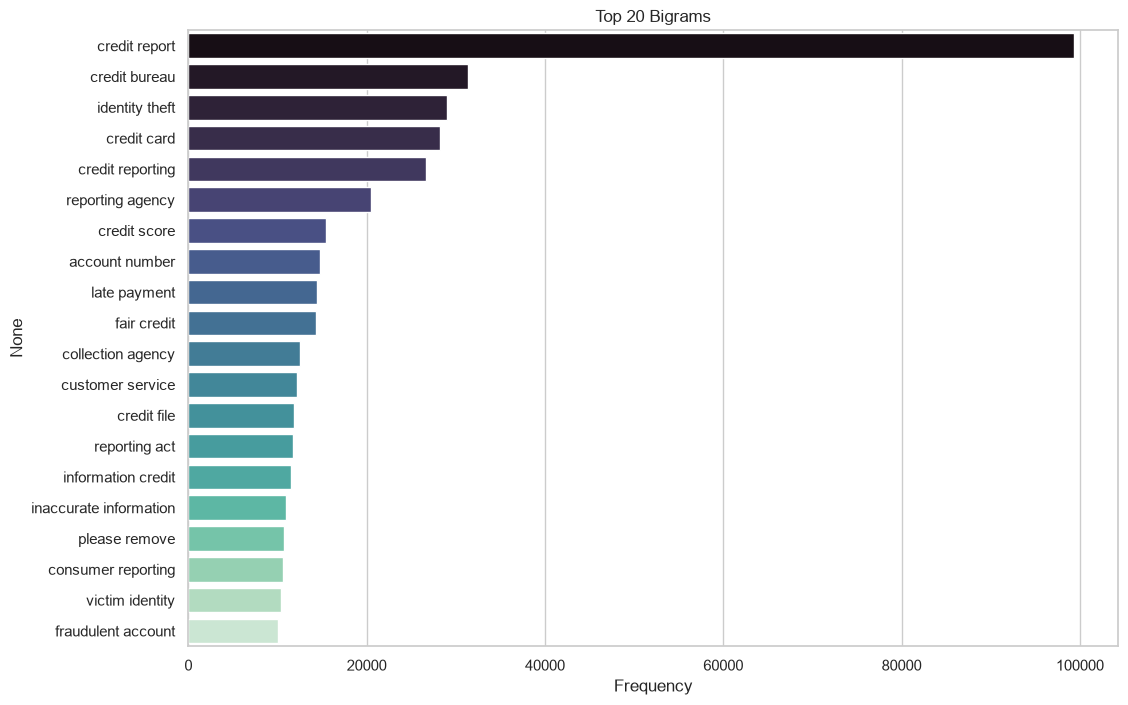

In [90]:
plt.figure(figsize=(12,8))

sns.barplot(

    x="Frequency",

    y=bigram_counts.index,

    data=bigram_counts,

    palette="mako"

)

plt.title("Top 20 Bigrams")

plt.show()


Students often discover phrases such as


credit report

customer service

loan modification

credit card

late payment

These are much more informative than individual words.

Top Trigrams

In [91]:
trigram = CountVectorizer(

    ngram_range=(3,3),

    max_features=20

)

X = trigram.fit_transform(df_clean["clean_text"])

Frequency

In [92]:
trigram_counts = pd.DataFrame(

    X.sum(axis=0).A1,

    index=trigram.get_feature_names_out(),

    columns=["Frequency"]

)

trigram_counts = trigram_counts.sort_values(

    by="Frequency",

    ascending=False

)

trigram_counts.head(20)

,Frequency
fair credit reporting,11714
credit reporting act,11665
consumer reporting agency,10476
victim identity theft,9338
credit reporting agency,9116
opened balance account,6564
information credit report,6558
acct opened balance,6235
account credit report,5980
account acct opened,5853



Visualization

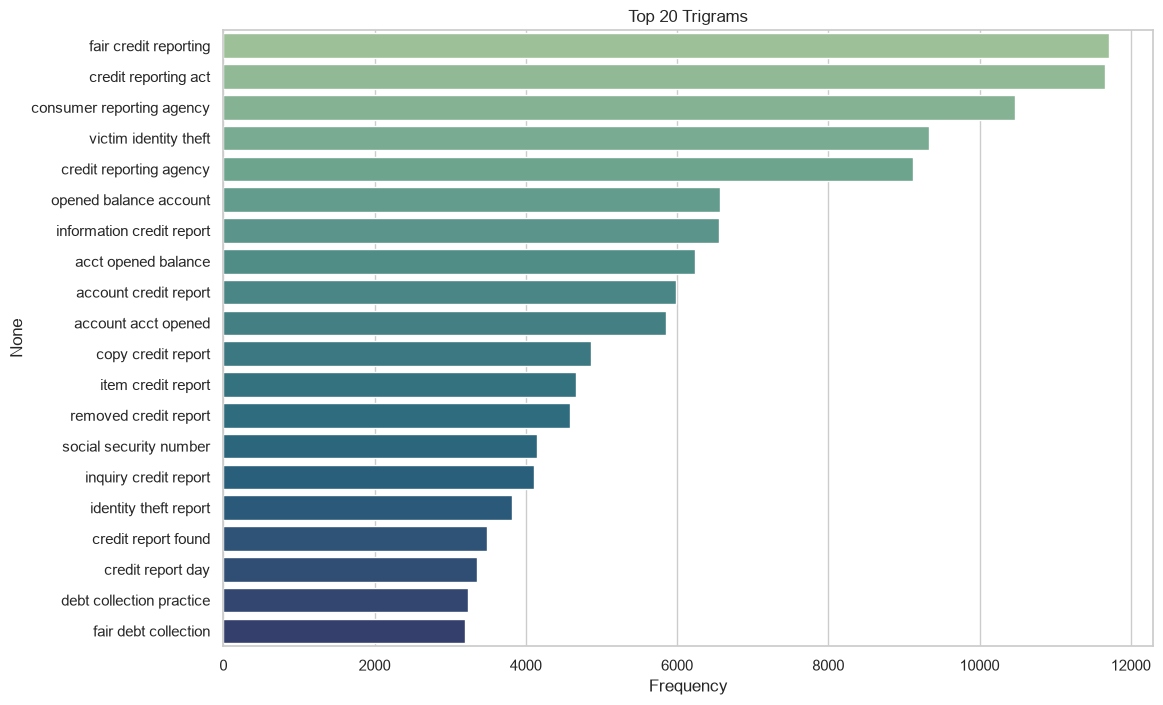

In [93]:
plt.figure(figsize=(12,8))

sns.barplot(

    x="Frequency",

    y=trigram_counts.index,

    data=trigram_counts,

    palette="crest"

)

plt.title("Top 20 Trigrams")

plt.show()

Why N-grams?


Instead of learning

```
credit

card
```

the model learns

```
credit card
```

which contains much richer semantic information.

Complaint Length Before vs After Cleaning

In [94]:
df_clean["Original_Length"] = df["narrative"].str.split().apply(len)

df_clean["Cleaned_Length"] = df_clean["clean_text"].str.split().apply(len)

Visualization

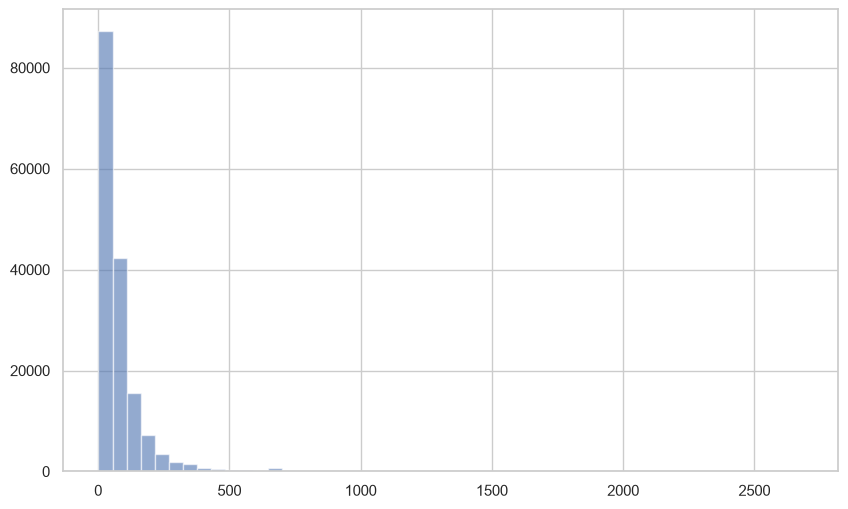

In [95]:
plt.figure(figsize=(10,6))

plt.hist(

    df_clean["Original_Length"],

    bins=50,

    alpha=0.6,

    label="Original"

)

plt.show()



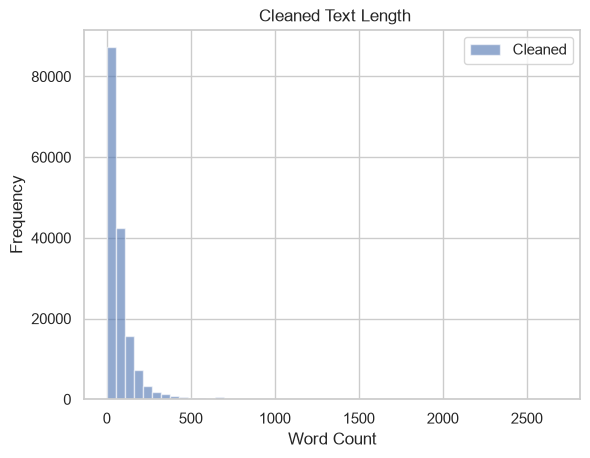

In [96]:

plt.hist(

    df_clean["Cleaned_Length"],

    bins=50,

    alpha=0.6,

    label="Cleaned"

)

plt.legend()

plt.title(" Cleaned Text Length")

plt.xlabel("Word Count")

plt.ylabel("Frequency")

plt.show()



Observation


* Cleaning reduces text length.
* Noise words disappear.
* Important keywords remain.

Word Cloud by Product Category

This is a powerful business visualization.

In [97]:
# category = "Mortgage"

# text = " ".join(

#     df_clean[

#         df_clean["product"] == category

#     ]["clean_text"]

# )

# wordcloud = WordCloud(

#     width=1000,

#     height=500,

#     background_color="white"

# ).generate(text)

# plt.figure(figsize=(14,6))

# plt.imshow(wordcloud)

# plt.axis("off")

# plt.title(category)

# plt.show()


Try this for every product category.

see the vocabulary differences between complaint types.

Most Common Banking Terms

Let's focus on domain-specific keywords.

In [98]:
keywords = [

    "loan",

    "credit",

    "bank",

    "payment",

    "mortgage",

    "debt",

    "interest",

    "account",

    "report",

    "collection"

]

Count occurrences

In [99]:

counts = {}

for word in keywords:

    counts[word] = all_text.split().count(word)

keyword_df = pd.DataFrame(

    counts.items(),

    columns=["Keyword","Frequency"]

)

Visualization

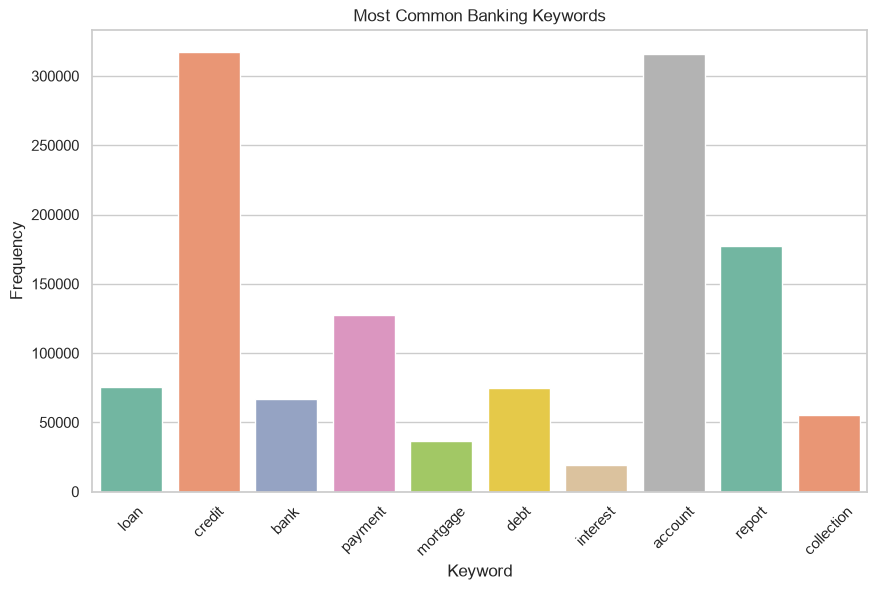

In [100]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=keyword_df,

    x="Keyword",

    y="Frequency",

    palette="Set2"

)

plt.title("Most Common Banking Keywords")

plt.xticks(rotation=45)

plt.show()

Business Insight

These keywords reveal the dominant issues customers face and can help banks prioritize service improvements.

Words per Complaint Category (Advanced)

In [101]:
for category in df_clean["product"].unique():

    print("="*70)

    print(category)

    print()

    text = " ".join(

        df_clean[

            df_clean["product"] == category

        ]["clean_text"]

    )

    freq = Counter(text.split())

    print(freq.most_common(10))

credit_card

[('card', 37862), ('credit', 33268), ('account', 28506), ('payment', 17876), ('bank', 14078), ('charge', 13869), ('would', 13002), ('time', 12595), ('one', 11316), ('received', 10273)]
retail_banking

[('account', 45472), ('bank', 26096), ('money', 15977), ('would', 10500), ('day', 9942), ('told', 9681), ('check', 9313), ('fund', 9162), ('time', 8675), ('transaction', 8135)]
credit_reporting

[('credit', 224547), ('account', 188590), ('report', 144587), ('information', 107572), ('reporting', 80306), ('consumer', 50212), ('payment', 45660), ('dispute', 42434), ('letter', 39075), ('day', 39048)]
mortgages_and_loans

[('payment', 47361), ('loan', 44211), ('mortgage', 26602), ('would', 22593), ('account', 19100), ('time', 18356), ('credit', 15874), ('told', 15638), ('company', 14550), ('received', 14327)]
debt_collection

[('debt', 42663), ('credit', 39201), ('account', 34483), ('collection', 22212), ('report', 20639), ('company', 18872), ('information', 16211), ('letter', 124

understand how vocabulary changes across categories.

Zipf's Law Visualization (Optional Advanced)

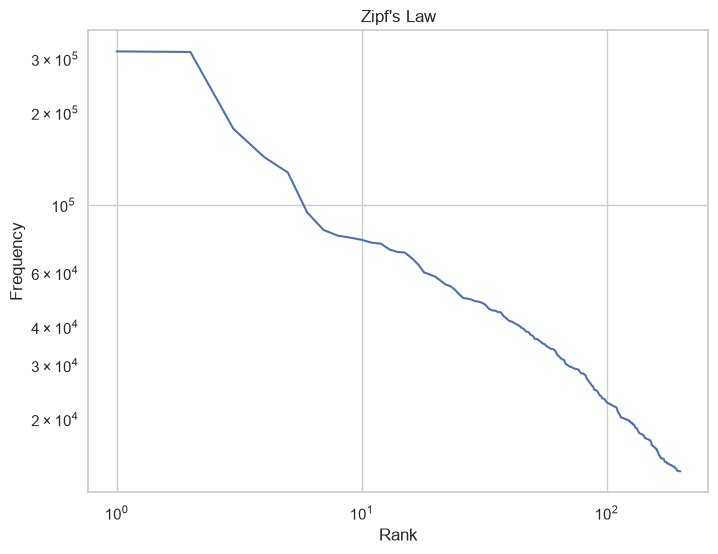

In [102]:
freq = pd.DataFrame(

    word_freq.most_common(200),

    columns=["Word","Frequency"]

)

freq["Rank"] = range(1,201)

plt.figure(figsize=(8,6))

plt.loglog(

    freq["Rank"],

    freq["Frequency"]

)

plt.xlabel("Rank")

plt.ylabel("Frequency")

plt.title("Zipf's Law")

plt.show()


Feature Engineering & Text Vectorization

Machine Learning algorithms **cannot understand text directly**.

Example:

```text
"I love Machine Learning"
```

For humans, this sentence has meaning.

For a machine, it is just characters.

So we must convert text into **numbers**.

This process is called **Vectorization**.

NLP Pipeline

```text
Raw Text
      │
      ▼
Preprocessing
      │
      ▼
Clean Text
      │
      ▼
Feature Engineering
      │
      ▼
CountVectorizer
      │
      ▼
TF-IDF
      │
      ▼
Machine Learning

Select Features and Target

Our dataset now contains many columns.

For NLP we need only

* Cleaned complaint
* Product Category

In [103]:
X = df_clean["clean_text"]

y = df_clean["product"]

Check Target Distribution

In [104]:
y.value_counts()

product
credit_reporting       91172
debt_collection        23148
mortgages_and_loans    18990
credit_card            15566
retail_banking         13535
Name: count, dtype: int64

Why?

Always inspect the target before training.

Questions to ask:

* Is the dataset balanced?

* Which category has maximum complaints?

* Which category has minimum complaints?

Train Test Split

Never train and test on the same data.

We'll use

* 80% Training
* 20% Testing

In [105]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

Why Stratify?

Suppose

Mortgage = 40%

Debt Collection = 30%

Credit Card = 20%

Others = 10%

Without stratification,

the test data may become unbalanced.

`stratify=y`

preserves the same class distribution in both training and testing.

In [106]:
print("Training Samples :", X_train.shape)

print("Testing Samples :", X_test.shape)

Training Samples : (129928,)
Testing Samples : (32483,)


Bag of Words (CountVectorizer)

## What is Bag of Words?

Imagine three complaints.

```text
Complaint 1

credit card issue
```

```text
Complaint 2

loan payment delayed
```

```text
Complaint 3

credit payment failed
```

Vocabulary

```text
credit

card

issue

loan

payment

delayed

failed
```

Machine converts them into numbers.

| Complaint | credit | card | loan | payment | issue |
| --------- | ------ | ---- | ---- | ------- | ----- |
| 1         | 1      | 1    | 0    | 0       | 1     |
| 2         | 0      | 0    | 1    | 1       | 0     |
| 3         | 1      | 0    | 0    | 1       | 0     |

This is called **Bag of Words**.

Build CountVectorizer

In [107]:
from sklearn.feature_extraction.text import CountVectorizer

count_vectorizer = CountVectorizer()

Fit only on training data

In [108]:
X_train_count = count_vectorizer.fit_transform(X_train)

X_test_count = count_vectorizer.transform(X_test)

Check Matrix Shape

In [109]:
print(X_train_count.shape)

(129928, 41711)


Vocabulary Size

In [110]:
print(

    "Vocabulary Size :",

    len(count_vectorizer.vocabulary_)

)

Vocabulary Size : 41711


View Vocabulary

In [111]:
vocab = list(

    count_vectorizer.vocabulary_.keys()

)

print(vocab[:50])

['found', 'online', 'shopping', 'site', 'named', 'using', 'search', 'engine', 'initial', 'woman', 'bike', 'believed', 'lucky', 'break', 'spotting', 'buck', 'placed', 'order', 'account', 'checkout', 'noticed', 'something', 'unusual', 'receive', 'normal', 'confirmation', 'email', 'company', 'required', 'however', 'receipt', 'skeptisum', 'returned', 'attempting', 'contact', 'customer', 'service', 'support', 'thing', 'really', 'began', 'look', 'suspicious', 'provided', 'way', 'merchant', 'via', 'phone', 'number', 'non']


Most Frequent Words

In [112]:
word_counts = X_train_count.sum(axis=0)

word_counts = np.asarray(word_counts).flatten()

words = count_vectorizer.get_feature_names_out()

frequency = pd.DataFrame({

    "Word":words,

    "Frequency":word_counts

})

frequency = frequency.sort_values(

    by="Frequency",

    ascending=False

)

frequency.head(20)

,Word,Frequency
8719,credit,254089
329,account,253388
30433,report,142074
18857,information,115685
26152,payment,102049
30456,reporting,75765
36646,time,66217
7184,company,63569
40762,would,62691
9293,day,61354


Visualization

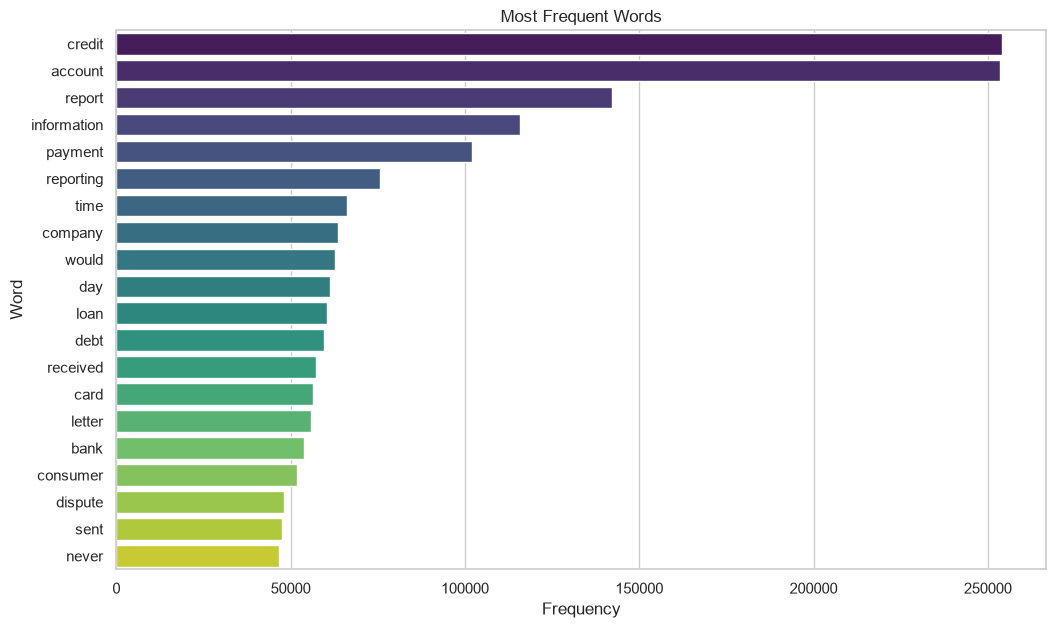

In [113]:
plt.figure(figsize=(12,7))

sns.barplot(

    data=frequency.head(20),

    y="Word",

    x="Frequency",

    palette="viridis"

)

plt.title("Most Frequent Words")

plt.show()

Limit Vocabulary

Instead of learning every word

we can keep only

Top 10,000

```python
count_vectorizer = CountVectorizer(

    max_features=10000

)
```

Benefits

✔ Faster

✔ Less memory

✔ Better generalization

Remove Rare Words

In [114]:
CountVectorizer(

    min_df=5

)

,"min_df min_df: float in range [0.0, 1.0] or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float, the parameter represents a proportion of documents, integerabsolute counts.This parameter is ignored if vocabulary is not None.",5
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"stop_words stop_words: {'english'}, list, default=NoneIf 'english', a built-in stop word list for English is used.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str or None, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp select tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentword n-grams or char n-grams to be extracted. All values of n suchsuch that min_n <= n <= max_n will be used. For example an``ngram_range`` of ``(1, 1)`` means only unigrams, ``(1, 2)`` meansunigrams and bigrams, and ``(2, 2)`` means only bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"



Meaning

Ignore words appearing

less than

5 documents.

Remove Extremely Common Words

In [115]:
CountVectorizer(

    max_df=0.90

)

,"max_df max_df: float in range [0.0, 1.0] or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float, the parameter represents a proportion of documents, integerabsolute counts.This parameter is ignored if vocabulary is not None.",0.9
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"stop_words stop_words: {'english'}, list, default=NoneIf 'english', a built-in stop word list for English is used.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str or None, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp select tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentword n-grams or char n-grams to be extracted. All values of n suchsuch that min_n <= n <= max_n will be used. For example an``ngram_range`` of ``(1, 1)`` means only unigrams, ``(1, 2)`` meansunigrams and bigrams, and ``(2, 2)`` means only bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"


Meaning

Ignore words

appearing in

90% documents.

Include Bigrams

Instead of

```text
credit

card
```

Learn

```text
credit card
```


In [116]:
count_vectorizer = CountVectorizer(

    ngram_range=(1,2),

    max_features=15000

)

observe improved contextual representation.

TF-IDF


Bag of Words counts frequency only.

Problem

The word

```text
customer
```

appears everywhere.

So it isn't very useful.

TF-IDF gives higher weight to

rare

important

words.


Formula

```
TF-IDF

=

Term Frequency

×

Inverse Document Frequency
```

* High frequency **within a document** → important.
* High frequency **across all documents** → less informative.


Build TF-IDF Vectorizer

In [117]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(

    max_features=15000,

    min_df=5,

    max_df=0.90,

    ngram_range=(1,2)

)

Fit

In [118]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [119]:
print(X_train_tfidf.shape)

(129928, 15000)


TF-IDF Vocabulary

In [120]:
print(

    "Vocabulary Size:",

    len(tfidf.vocabulary_)

)

Vocabulary Size: 15000


Inspect TF-IDF Features

In [121]:
feature_names = tfidf.get_feature_names_out()

print(feature_names[:50])

['abide' 'ability' 'ability consumer' 'ability get' 'ability obtain'
 'ability pay' 'able' 'able access' 'able assist' 'able close'
 'able contact' 'able disregard' 'able find' 'able get' 'able help'
 'able locate' 'able make' 'able obtain' 'able pay' 'able provide'
 'able reach' 'able request' 'able see' 'able speak' 'able thing'
 'able use' 'able verify' 'able work' 'abruptly' 'absence' 'absent'
 'absent proof' 'absolute' 'absolute deficiency' 'absolutely'
 'absolutely idea' 'absolutely nothing' 'absurd' 'abuse' 'abused'
 'abusive' 'acc' 'accept' 'accept payment' 'accept presented'
 'accept statement' 'acceptable' 'acceptance' 'accepted'
 'accepted reporting']


Compare CountVectorizer vs TF-IDF

| CountVectorizer               | TF-IDF                                     |
| ----------------------------- | ------------------------------------------ |
| Counts words                  | Weights words                              |
| Simple                        | Smarter weighting                          |
| High-frequency words dominate | Rare but informative words gain importance |
| Fast                          | Slightly slower                            |
| Great baseline                | Usually better for text classification     |

Save Vectorizer (Optional)

Useful for deployment later.

In [122]:
import joblib

joblib.dump(

    tfidf,

    "tfidf_vectorizer.pkl"

)

['tfidf_vectorizer.pkl']

Building and Comparing Machine Learning Models

Learning Objective

Now that we've converted our complaint text into **TF-IDF features**, it's time to train machine learning models.

Instead of training only one algorithm, we'll compare multiple models—the same approach followed in real industry projects.

We will compare:

1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear Support Vector Machine (Linear SVM)
4. Random Forest
5. XGBoost (Optional)

Why Compare Multiple Models?

Different algorithms learn differently.

For example:

* **Naive Bayes** is extremely fast and often performs surprisingly well on text.
* **Logistic Regression** provides a strong and interpretable baseline.
* **Linear SVM** is widely recognized as one of the best classical algorithms for text classification.
* **Random Forest** can model complex relationships but often struggles with sparse TF-IDF features.
* **XGBoost** is powerful for structured data and can sometimes improve performance.

Create a Results Dictionary

We'll store evaluation metrics for each model.

In [123]:
results = {}

Train Multinomial Naive Bayes

In [124]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](5,)","[12453.,72937.,18518.,15192.,10828.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](5,)","[-2.35,-0.58,-1.95,-2.15,-2.48]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U19](5,)","['credit_card','credit_reporting','debt_collection','mortgages_and_loans', 'retail_banking']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](5, 15000)","[[ 1.32, 18.64, 0.85,..., 4.02, 3.57, 0.68], [ 28.22,128.32, 27.58,..., 6.31, 4.69, 0.8 ], [ 2.69, 27.62, 1.34,..., 3.07, 2.15, 3. ], [ 2.15, 24.33, 0.17,..., 2.46, 1.88, 6.11], [ 1.28, 12.34, 0.02,..., 2.53, 1.5 , 1.14]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](5, 15000)","[[-10.74, -8.6 ,-10.96,..., -9.96,-10.06,-11.06], [ -9.79, -8.3 , -9.81,...,-11.18,-11.43,-12.58], [-10.58, -8.53,-11.04,...,-10.48,-10.74,-10.5 ], [-10.64, -8.55,-11.63,...,-10.54,-10.72, -9.82], [-10.58, -8.81,-11.38,...,-10.14,-10.48,-10.64]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15000


Prediction

In [125]:
y_pred_nb = nb_model.predict(X_test_tfidf)

Evaluate

In [126]:
from sklearn.metrics import accuracy_score

nb_accuracy = accuracy_score(
    y_test,
    y_pred_nb
)

print("Naive Bayes Accuracy :", round(nb_accuracy,4))

Naive Bayes Accuracy : 0.8372


Classification Report

In [127]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_nb
    )
)

                     precision    recall  f1-score   support

        credit_card       0.70      0.78      0.74      3113
   credit_reporting       0.92      0.86      0.89     18235
    debt_collection       0.76      0.71      0.73      4630
mortgages_and_loans       0.71      0.89      0.79      3798
     retail_banking       0.82      0.89      0.86      2707

           accuracy                           0.84     32483
          macro avg       0.78      0.83      0.80     32483
       weighted avg       0.85      0.84      0.84     32483



Confusion Matrix

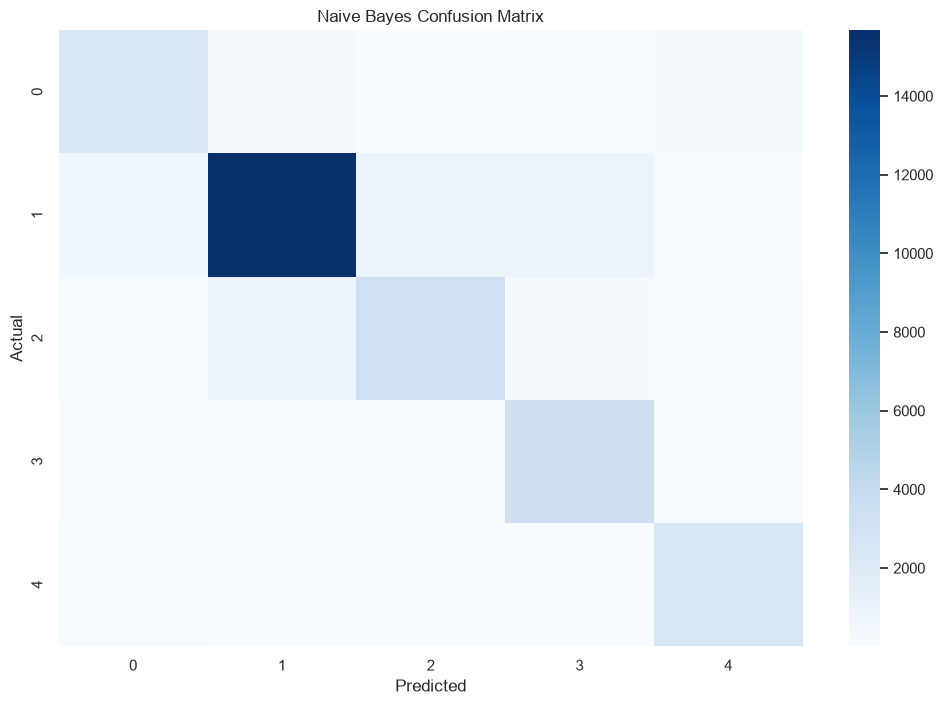

In [128]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_nb
)

plt.figure(figsize=(12,8))

sns.heatmap(
    cm,
    cmap="Blues",
    fmt="d"
)

plt.title("Naive Bayes Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

Store Results

In [129]:
results["Naive Bayes"] = nb_accuracy

Train Logistic Regression

In [130]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_tfidf,
    y_train
)


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

Prediction

In [131]:
y_pred_lr = lr_model.predict(
    X_test_tfidf
)

Accuracy

In [132]:
lr_accuracy = accuracy_score(
    y_test,
    y_pred_lr
)

print(
    "Logistic Regression Accuracy :",
    round(lr_accuracy,4)
)

Logistic Regression Accuracy : 0.8832


Classification Report

In [133]:
print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

                     precision    recall  f1-score   support

        credit_card       0.81      0.79      0.80      3113
   credit_reporting       0.91      0.94      0.93     18235
    debt_collection       0.83      0.75      0.79      4630
mortgages_and_loans       0.86      0.84      0.85      3798
     retail_banking       0.87      0.89      0.88      2707

           accuracy                           0.88     32483
          macro avg       0.86      0.84      0.85     32483
       weighted avg       0.88      0.88      0.88     32483



Store

In [134]:
results["Logistic Regression"] = lr_accuracy

 Train Linear SVM

Linear SVM is considered one of the strongest classical models for NLP.

In [135]:

from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(
    X_train_tfidf,
    y_train
)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

Prediction

In [136]:
y_pred_svm = svm_model.predict(
    X_test_tfidf
)

Accuracy

In [137]:
svm_accuracy = accuracy_score(
    y_test,
    y_pred_svm
)

print(
    "Linear SVM Accuracy :",
    round(svm_accuracy,4)
)

Linear SVM Accuracy : 0.8823


Classification Report

In [138]:
print(
    classification_report(
        y_test,
        y_pred_svm
    )
)

                     precision    recall  f1-score   support

        credit_card       0.80      0.79      0.79      3113
   credit_reporting       0.92      0.94      0.93     18235
    debt_collection       0.82      0.76      0.79      4630
mortgages_and_loans       0.85      0.83      0.84      3798
     retail_banking       0.87      0.88      0.87      2707

           accuracy                           0.88     32483
          macro avg       0.85      0.84      0.85     32483
       weighted avg       0.88      0.88      0.88     32483



Store

In [139]:
results["Linear SVM"] = svm_accuracy

Train Random Forest

In [140]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_tfidf,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

Prediction

In [141]:
y_pred_rf = rf_model.predict(
    X_test_tfidf
)

Accuracy

In [142]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy :",
    round(rf_accuracy,4)
)

Random Forest Accuracy : 0.8837


Store

In [145]:
results["Random Forest"] = rf_accuracy

XGBoost (Optional)

In [146]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 780.5 kB/s  0:00:03 eta 0:00:01


In [148]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Encode target labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="mlogloss",
    n_jobs = -1
)

xgb_model.fit(
    X_train_tfidf,
    y_train_encoded
)

y_pred_xgb = xgb_model.predict(
    X_test_tfidf
)

xgb_accuracy = accuracy_score(
    y_test_encoded,
    y_pred_xgb
)

results["XGBoost"] = xgb_accuracy

print(
    "XGBoost Accuracy:",
    round(xgb_accuracy,4)
)

XGBoost Accuracy: 0.8774


Compare Model Performance

In [149]:
results_df = pd.DataFrame(
    results.items(),
    columns=["Model","Accuracy"]
)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df


print(results_df)

                 Model  Accuracy
3        Random Forest  0.883724
1  Logistic Regression  0.883231
2           Linear SVM  0.882338
4              XGBoost  0.877382
0          Naive Bayes  0.837238


Visualize Model Comparison

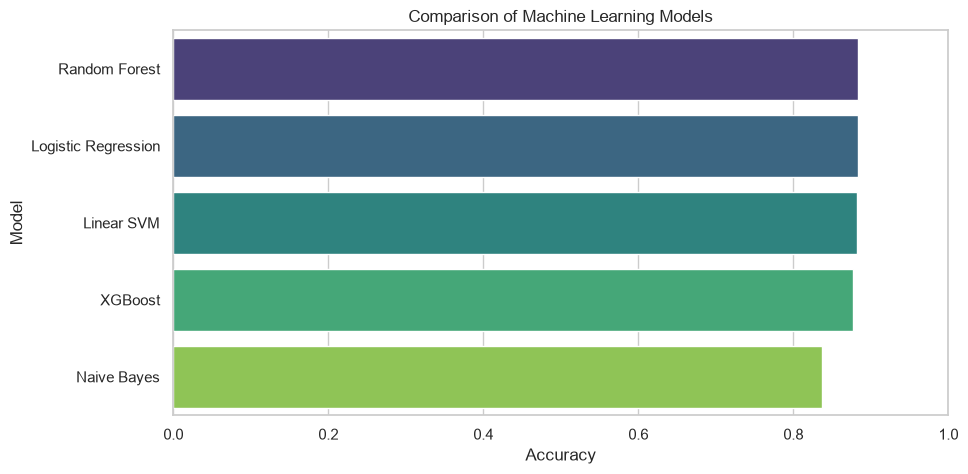

In [150]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model",
    palette="viridis"
)

plt.title("Comparison of Machine Learning Models")

plt.xlim(0,1)

plt.show()

Discussion

Why might Random forest perform best?

* Handles high-dimensional sparse TF-IDF vectors efficiently.
* Finds an optimal separating hyperplane.
* Less affected by noisy features than some tree-based methods.

Why does Naive Bayes remain popular?

* Extremely fast to train and predict.
* Strong baseline for text classification.
* Works well even with relatively small datasets.

Why might Random Forest lag behind?

* Sparse TF-IDF matrices are not the ideal input for tree-based algorithms.
* Requires more memory and computation.